In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [3]:
import pandas as pd

df = pd.read_csv('train.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'train.csv'

In [4]:
import pandas as pd

df = pd.read_csv('Sample - Superstore.csv')
df.head()

UnicodeDecodeError: 'utf-8' codec can't decode byte 0xa0 in position 2944: invalid start byte

In [5]:
print(uploaded.keys())


dict_keys(['Sample - Superstore.csv'])


In [6]:
import pandas as pd

df = pd.read_csv('Sample - Superstore.csv', encoding='latin1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [7]:
print("Rows and Columns:", df.shape)

Rows and Columns: (9994, 21)


In [8]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [10]:
print(df.isnull().sum())

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [11]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [12]:
df = df.drop_duplicates()
print("After removing duplicates:", df.shape)

After removing duplicates: (9994, 21)


In [13]:
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
print(df['Order Date'].dtype)

datetime64[ns]


In [14]:
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month_name()

df[['Order Date', 'Year', 'Month']].head()

,Order Date,Year,Month
0,2016-11-08,2016,November
1,2016-11-08,2016,November
2,2016-06-12,2016,June
3,2015-10-11,2015,October
4,2015-10-11,2015,October


In [15]:
print("Total Sales:", df['Sales'].sum())
print("Total Profit:", df['Profit'].sum())
print("Total Orders:", df['Order ID'].nunique())

Total Sales: 2297200.8603
Total Profit: 286397.0217
Total Orders: 5009


In [16]:
monthly_sales = df.groupby('Month')['Sales'].sum()
print(monthly_sales)

Month
April        137762.1286
August       159044.0630
December     325293.5035
February      59751.2514
January       94924.8356
July         147238.0970
June         152718.6793
March        205005.4888
May          155028.8117
November     352461.0710
October      200322.9847
September    307649.9457
Name: Sales, dtype: float64


In [17]:
region_sales = df.groupby('Region')['Sales'].sum()
print(region_sales)

Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64


In [18]:
category_sales = df.groupby('Category')['Sales'].sum()
print(category_sales)

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64


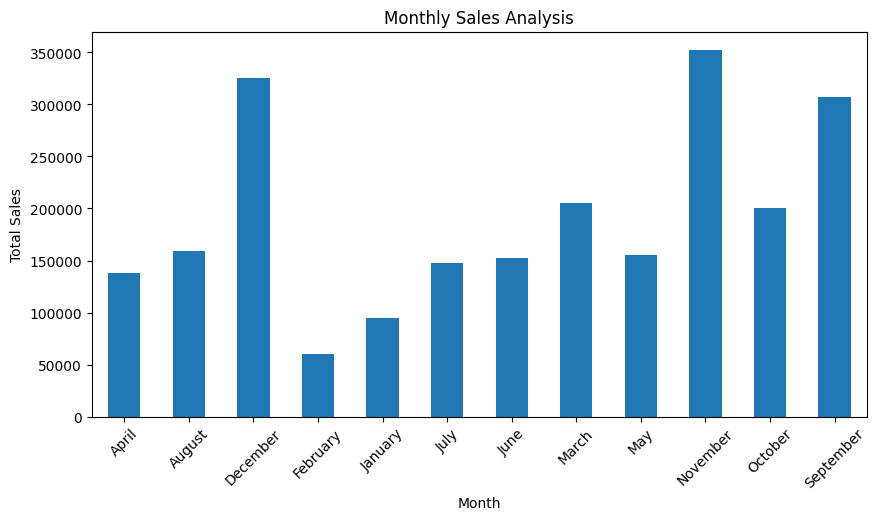

In [19]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind='bar', figsize=(10,5))
plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

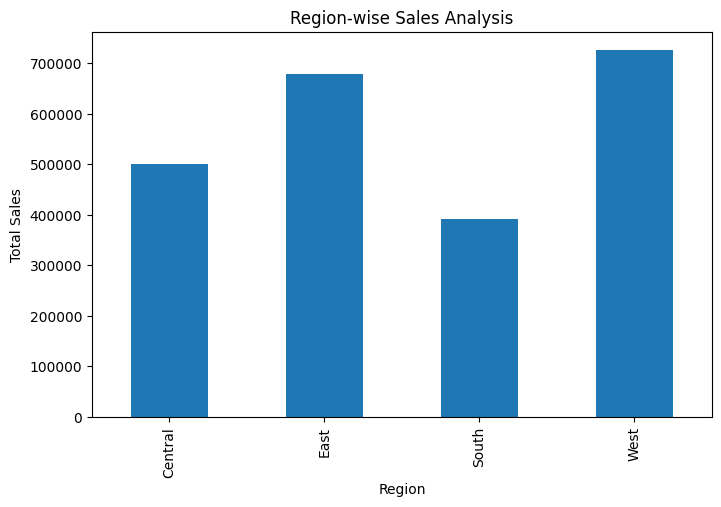

In [20]:
region_sales.plot(kind='bar', figsize=(8,5))
plt.title('Region-wise Sales Analysis')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.show()

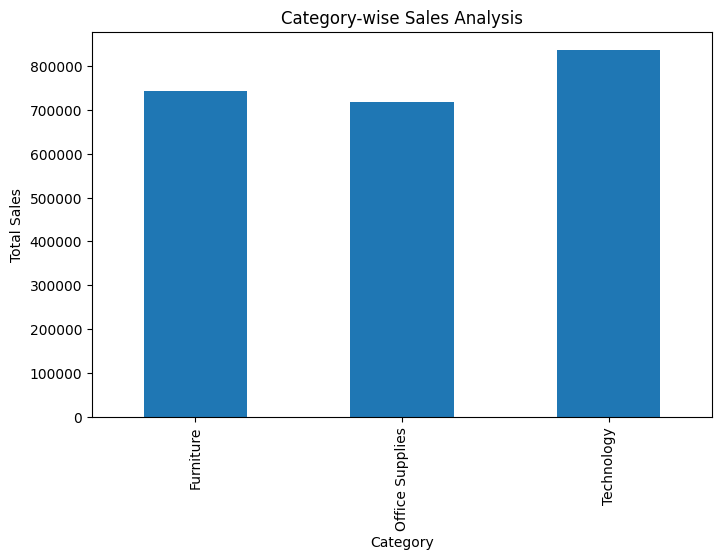

In [21]:
category_sales.plot(kind='bar', figsize=(8,5))
plt.title('Category-wise Sales Analysis')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.show()

In [22]:
region_profit = df.groupby('Region')['Profit'].sum()
print(region_profit)

Region
Central     39706.3625
East        91522.7800
South       46749.4303
West       108418.4489
Name: Profit, dtype: float64


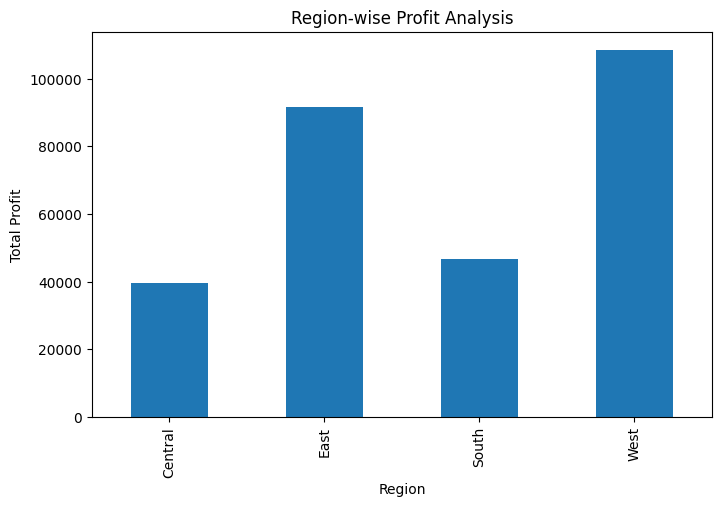

In [23]:
region_profit.plot(kind='bar', figsize=(8,5))
plt.title('Region-wise Profit Analysis')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.show()

In [24]:
top_products = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)
print(top_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


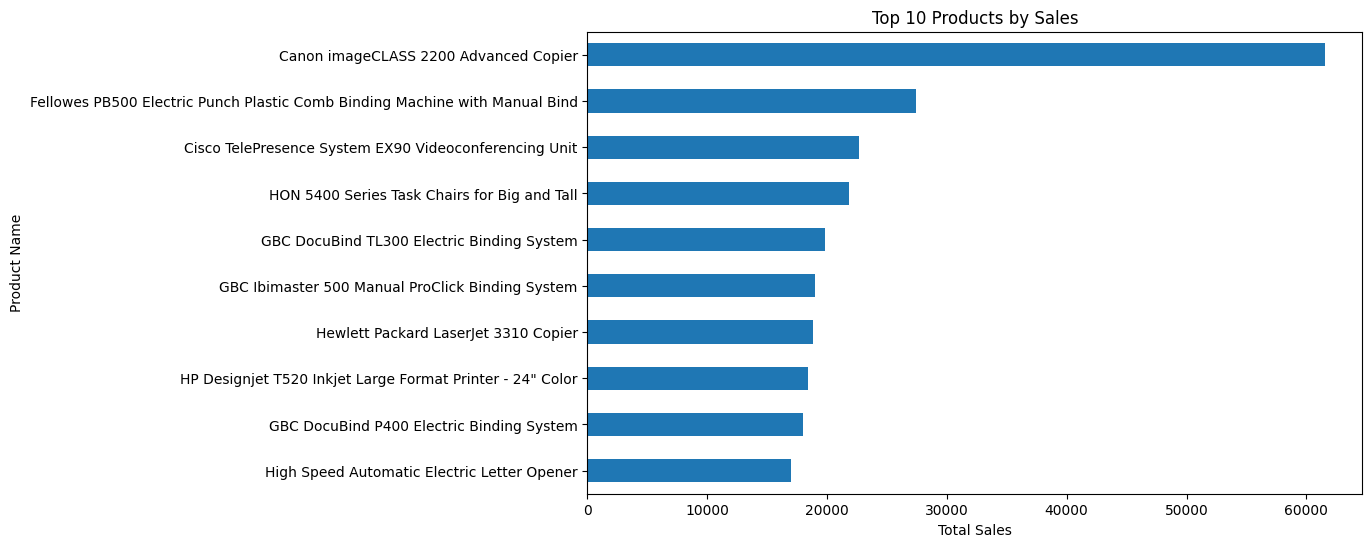

In [25]:
top_products.sort_values().plot(kind='barh', figsize=(10,6))
plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Name')
plt.show()

In [26]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793


In [27]:
import plotly.express as px

fig = px.bar(
    df.groupby('Region', as_index=False)['Sales'].sum(),
    x='Region',
    y='Sales',
    color='Region',
    title='Interactive Region-wise Sales'
)
fig.show()

In [28]:
category_data = df.groupby('Category', as_index=False)['Sales'].sum()

fig = px.pie(
    category_data,
    names='Category',
    values='Sales',
    title='Sales by Product Category'
)
fig.show()

In [29]:
monthly_data = df.set_index('Order Date').resample('MS')['Sales'].sum().reset_index()

fig = px.line(
    monthly_data,
    x='Order Date',
    y='Sales',
    title='Monthly Sales Trend',
    markers=True
)
fig.show()

In [30]:
fig = px.scatter(
    df,
    x='Sales',
    y='Profit',
    color='Category',
    hover_data=['Region', 'Segment'],
    title='Sales vs Profit Analysis'
)
fig.show()

In [31]:
import ipywidgets as widgets
from IPython.display import display

In [32]:
def update_dashboard(region, category):
    filtered = df.copy()

    if region != 'All':
        filtered = filtered[filtered['Region'] == region]

    if category != 'All':
        filtered = filtered[filtered['Category'] == category]

    print("Total Sales:", round(filtered['Sales'].sum(), 2))
    print("Total Profit:", round(filtered['Profit'].sum(), 2))
    print("Total Orders:", filtered['Order ID'].nunique())

In [36]:
def update_dashboard(region, category):
    filtered = df.copy()

    if region != 'All':
        filtered = filtered[filtered['Region'] == region]

    if category != 'All':
        filtered = filtered[filtered['Category'] == category]

    print("Total Sales:", round(filtered['Sales'].sum(), 2))
    print("Total Profit:", round(filtered['Profit'].sum(), 2))
    print("Total Orders:", filtered['Order ID'].nunique())

    monthly = filtered.groupby(
        pd.Grouper(key='Order Date', freq='MS')
    )['Sales'].sum().reset_index()

    fig = px.line(
        monthly,
        x='Order Date',
        y='Sales',
        markers=True,
        title='Monthly Sales Trend'
    )

    fig.show()

In [37]:
region_options = ['All'] + sorted(df['Region'].dropna().unique().tolist())
category_options = ['All'] + sorted(df['Category'].dropna().unique().tolist())

region_dropdown = widgets.Dropdown(
    options=region_options,
    description='Region:'
)

category_dropdown = widgets.Dropdown(
    options=category_options,
    description='Category:'
)

In [38]:
widgets.interact(
    update_dashboard,
    region=region_dropdown,
    category=category_dropdown
);

interactive(children=(Dropdown(description='Region:', options=('All', 'Central', 'East', 'South', 'West'), val…

In [39]:
print("INTERACTIVE SALES DASHBOARD")
print("===========================")

INTERACTIVE SALES DASHBOARD


In [41]:
print("Total Records:", len(df))

Total Records: 9994


In [40]:
print("Total Categories:", df['Category'].nunique())

Total Categories: 3


In [43]:
print("Total Regions:", df['Region'].nunique())

Total Regions: 4


In [42]:
region_sales = df.groupby('Region')['Sales'].sum()

print("Highest Sales Region:", region_sales.idxmax())
print("Highest Sales:", round(region_sales.max(), 2))

Highest Sales Region: West
Highest Sales: 725457.82


In [44]:
print("SALES ANALYTICS - INTERACTIVE DASHBOARD")

SALES ANALYTICS - INTERACTIVE DASHBOARD


In [45]:
monthly_sales = df.set_index('Order Date').resample('MS')['Sales'].sum()

fig = px.line(
    x=monthly_sales.index,
    y=monthly_sales.values,
    title='Monthly Sales Analysis',
    labels={'x': 'Month', 'y': 'Sales'}
)

fig.show()

In [46]:
fig.write_html("monthly_sales_dashboard.html")

In [47]:
from google.colab import files
files.download("monthly_sales_dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
print("""
Project: Interactive Dashboard Development

Objective:
To analyze sales data and display important
business insights using interactive charts.
""")


Project: Interactive Dashboard Development

Objective:
To analyze sales data and display important
business insights using interactive charts.



In [49]:
print("Dataset Name: Superstore Sales Dataset")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Name: Superstore Sales Dataset
Total Rows: 9994
Total Columns: 23


In [50]:
print("""
1. Data Cleaning
2. Missing Value Checking
3. Duplicate Removal
4. Sales Analysis
5. Profit Analysis
6. Region-wise Analysis
7. Category-wise Analysis
8. Monthly Sales Analysis
""")


1. Data Cleaning
2. Missing Value Checking
3. Duplicate Removal
4. Sales Analysis
5. Profit Analysis
6. Region-wise Analysis
7. Category-wise Analysis
8. Monthly Sales Analysis



In [51]:
print("""
Tools:
1. Python
2. Google Colab
3. Pandas
4. Matplotlib
5. Plotly
6. Kaggle Dataset
""")


Tools:
1. Python
2. Google Colab
3. Pandas
4. Matplotlib
5. Plotly
6. Kaggle Dataset



In [52]:
print("""
Conclusion:
The interactive dashboard helps users
understand sales trends, profits, regions
and product categories through visualizations.
""")


Conclusion:
The interactive dashboard helps users
understand sales trends, profits, regions
and product categories through visualizations.

